# Hydroelectric

[Review the theory and worked examples](../../section6/hydroelectricEnergy.md). [Download the exercise notebook](hydroelectric.ipynb).

## Chapter practice — 20 Python exercises

**5 easy · 10 medium · 5 hard.** All inputs are synthetic teaching data. Each solution starts collapsed in the book. Open it after trying your own code. Each solution runs independently.

### Exercise 01 — Net head

**Difficulty:** Easy

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** Gross head is 40 m and head loss 3 m. Calculate net head.

In [ ]:
# Your solution for hydro exercise 01.

#### Step-by-step answer — Hydro 01

1. Enter gross head and hydraulic losses.
2. Subtract losses before calculating useful head.
3. Check the head is positive and report it.

In [ ]:
# Step 1: Enter gross head and hydraulic losses.
gross, loss = 40, 3
# Step 2: Subtract losses before calculating useful head.
net = gross-loss
# Step 3: Check the head is positive and report it.
print(net,'m'); assert net == 37

37 m


**Interpretation:** Net head is 37 m; losses reduce rather than increase usable head.


### Exercise 02 — Electrical power

**Difficulty:** Easy

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** Use Q=10 m³/s, net head 30 m, efficiency 0.9, density 1000 kg/m³ and g 9.81 m/s². Calculate MW.

In [ ]:
# Your solution for hydro exercise 02.

#### Step-by-step answer — Hydro 02

1. Store parameters in SI units.
2. Convert hydraulic power to electricity and MW.
3. Check a hand-calculated result.

In [ ]:
# Step 1: Store parameters in SI units.
q, head, eta, rho, g = 10,30,0.9,1000,9.81
# Step 2: Convert hydraulic power to electricity and MW.
power = rho*g*q*head*eta/1e6
# Step 3: Check a hand-calculated result.
print(power,'MW'); assert abs(power-2.6487)<1e-12

2.6487 MW


**Interpretation:** 2.6487 MW omits generator clipping.


### Exercise 03 — Daily hydro energy

**Difficulty:** Easy

**Reference:** Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units).

**Task:** A hydro generator averages 2 MW for 24 hours. Calculate MWh and kWh.

In [ ]:
# Your solution for hydro exercise 03.

#### Step-by-step answer — Hydro 03

1. Enter average power and duration.
2. Integrate and convert energy units.
3. Verify and print both units.

In [ ]:
# Step 1: Enter average power and duration.
power, hours = 2,24
# Step 2: Integrate and convert energy units.
mwh=power*hours; kwh=mwh*1000
# Step 3: Verify and print both units.
print(mwh,'MWh;',kwh,'kWh'); assert mwh==48 and kwh==48000

48 MWh; 48000 kWh


**Interpretation:** The power must be an interval average for this calculation.


### Exercise 04 — Environmental reservation

**Difficulty:** Easy

**Reference:** Environmental/ecological releases: [International Finance Corporation, 2015](#reference-ifc2015), Chapters 7 and 12; the reservation is a teaching assumption.

**Task:** River flow is 8 m³/s and the environmental reservation is 3 m³/s. Calculate available turbine flow.

In [ ]:
# Your solution for hydro exercise 04.

#### Step-by-step answer — Hydro 04

1. Enter river flow and reservation.
2. Reserve water before assigning turbine flow.
3. Check non-negativity and report the result.

In [ ]:
# Step 1: Enter river flow and reservation.
river, reserve = 8,3
# Step 2: Reserve water before assigning turbine flow.
usable=max(river-reserve,0)
# Step 3: Check non-negativity and report the result.
print(usable,'m³/s'); assert usable==5

5 m³/s


**Interpretation:** This simplified reservation is not a site-specific environmental-flow prescription.


### Exercise 05 — Water volume

**Difficulty:** Easy

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** A turbine passes 3 m³/s for 2 hours. Calculate water volume.

In [ ]:
# Your solution for hydro exercise 05.

#### Step-by-step answer — Hydro 05

1. Convert hours to seconds.
2. Integrate the constant flow rate.
3. Check and label the volume.

In [ ]:
# Step 1: Convert hours to seconds.
seconds=2*3600
# Step 2: Integrate the constant flow rate.
volume=3*seconds
# Step 3: Check and label the volume.
print(volume,'m³'); assert volume==21600

21600 m³


**Interpretation:** Flow is volume per second; multiplying by hours without conversion is incorrect.


### Exercise 06 — Flow to power table

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** For river flows [2,5,10,20] m³/s, reserve 3, use head 25 m, eta 0.9, and a 2 MW rating. Tabulate usable flow and electrical MW.

In [ ]:
# Your solution for hydro exercise 06.

#### Step-by-step answer — Hydro 06

1. Calculate usable flow for each river condition.
2. Apply the hydraulic model and generator cap.
3. Check dry and clipped cases and print a table.

In [ ]:
import numpy as np
import pandas as pd
# Step 1: Calculate usable flow for each river condition.
river=np.array([2,5,10,20]); usable=np.maximum(river-3,0)
# Step 2: Apply the hydraulic model and generator cap.
power=np.minimum(1000*9.81*usable*25*0.9/1e6,2)
# Step 3: Check dry and clipped cases and print a table.
print(pd.DataFrame({'river_m3s':river,'usable_m3s':usable,'power_mw':power}))
assert power[0]==0 and power[-1]==2

   river_m3s  usable_m3s  power_mw
0          2           0  0.000000
1          5           2  0.441450
2         10           7  1.545075
3         20          17  2.000000


**Interpretation:** Capping power does not mean all available water must pass through the turbine.


### Exercise 07 — Generator flow limit

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** Find maximum turbine flow for a 2 MW generator, net head 25 m and eta 0.9. Compare against available flow 12 m³/s.

In [ ]:
# Your solution for hydro exercise 07.

#### Step-by-step answer — Hydro 07

1. Rearrange P=rho*g*Q*H*eta for Q.
2. Limit turbine flow to equipment capacity.
3. Recalculate power as a check.

In [ ]:
# Step 1: Rearrange P=rho*g*Q*H*eta for Q.
q_limit=2e6/(1000*9.81*25*0.9)
# Step 2: Limit turbine flow to equipment capacity.
q_turbine=min(12,q_limit); bypass=12-q_turbine
# Step 3: Recalculate power as a check.
power=1000*9.81*q_turbine*25*0.9/1e6
print(q_limit,'m³/s limit;',bypass,'m³/s bypass'); assert abs(power-2)<1e-12

9.061048816400499 m³/s limit; 2.9389511835995012 m³/s bypass


**Interpretation:** Bypass is water not used for generation; environmental flow has already been reserved.


### Exercise 08 — Quadratic head loss

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. The quadratic loss coefficient is assumed.

**Task:** At Q=[2,4,6] m³/s use gross head 30 m and loss=0.1Q² m. Calculate net head and MW at eta 0.9.

In [ ]:
# Your solution for hydro exercise 08.

#### Step-by-step answer — Hydro 08

1. Model the assumed flow-dependent loss.
2. Calculate head before calculating power.
3. Check head remains physically valid.

In [ ]:
import numpy as np
# Step 1: Model the assumed flow-dependent loss.
q=np.array([2,4,6]); loss=0.1*q**2
# Step 2: Calculate head before calculating power.
head=30-loss; power=1000*9.81*q*head*0.9/1e6
# Step 3: Check head remains physically valid.
print(head,'m;',power,'MW'); assert np.all(head>0) and np.all(head<30)

[29.6 28.4 26.4] m; [0.5226768 1.0029744 1.3985136] MW


**Interpretation:** The loss coefficient is synthetic and needs hydraulic calibration for a real conduit.


### Exercise 09 — Monthly durations

**Difficulty:** Medium

**Reference:** Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Data handling: [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html).

**Task:** Mean output is 2 MW in January and February 2025. Use pandas calendar month lengths to calculate MWh for each month.

In [ ]:
# Your solution for hydro exercise 09.

#### Step-by-step answer — Hydro 09

1. Create the two calendar months.
2. Multiply average output by actual month hours.
3. Verify the January and non-leap February results.

In [ ]:
import pandas as pd
# Step 1: Create the two calendar months.
months=pd.date_range('2025-01-01',periods=2,freq='MS')
# Step 2: Multiply average output by actual month hours.
energy=2*24*months.days_in_month.to_numpy()
# Step 3: Verify the January and non-leap February results.
print(energy,'MWh'); assert list(energy)==[1488,1344]

[1488 1344] MWh


**Interpretation:** Constant monthly mean output does not imply equal monthly energy.


### Exercise 10 — Flow-duration ranking

**Difficulty:** Medium

**Reference:** Flow-duration ranking: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapters 7–8; the plotting-position formula is stated in the exercise.

**Task:** Sort daily flows [8,2,10,4] descending and assign exceedance plotting positions rank/(n+1).

In [ ]:
# Your solution for hydro exercise 10.

#### Step-by-step answer — Hydro 10

1. Rank observed daily mean flows from largest to smallest.
2. Use the stated plotting-position convention.
3. Print paired values and check endpoints.

In [ ]:
import numpy as np
# Step 1: Rank observed daily mean flows from largest to smallest.
flow=np.sort([8,2,10,4])[::-1]
# Step 2: Use the stated plotting-position convention.
exceedance=np.arange(1,len(flow)+1)/(len(flow)+1)
# Step 3: Print paired values and check endpoints.
print(list(zip(exceedance,flow)))
assert np.all(np.diff(flow)<=0) and np.allclose(exceedance,[.2,.4,.6,.8])

[(0.2, 10), (0.4, 8), (0.6, 4), (0.8, 2)]


**Interpretation:** A duration curve loses chronology and cannot directly route reservoir storage.


### Exercise 11 — Efficiency sensitivity

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** At Q 8 m³/s and net head 40 m, compare efficiencies 0.75,0.85,0.95. Print MW and the gain from lowest to highest.

In [ ]:
# Your solution for hydro exercise 11.

#### Step-by-step answer — Hydro 11

1. Define conversion-efficiency scenarios.
2. Keep resource inputs fixed across scenarios.
3. Verify linear sensitivity and report gain.

In [ ]:
import numpy as np
# Step 1: Define conversion-efficiency scenarios.
eta=np.array([0.75,0.85,0.95])
# Step 2: Keep resource inputs fixed across scenarios.
power=1000*9.81*8*40*eta/1e6
# Step 3: Verify linear sensitivity and report gain.
print(power,'MW; gain:',power[-1]-power[0],'MW')
assert np.allclose(power/power[0],eta/eta[0])

[2.3544  2.66832 2.98224] MW; gain: 0.62784 MW


**Interpretation:** Real turbine efficiency varies with operating point; these are comparison assumptions.


### Exercise 12 — Pumped-storage round trip

**Difficulty:** Medium

**Reference:** Pumped-storage conversion: [Quaranta et al., 2025](#reference-jrc2025hydro), §2; efficiencies are illustrative.

**Task:** Store 100000 m³ through 100 m head. With pump efficiency 0.85 and generation efficiency 0.9, find gravitational, input and recovered MWh.

In [ ]:
# Your solution for hydro exercise 12.

#### Step-by-step answer — Hydro 12

1. Convert gravitational joules to MWh.
2. Account for pumping and generating conversion losses.
3. Check round-trip efficiency.

In [ ]:
import numpy as np
# Step 1: Convert gravitational joules to MWh.
stored=1000*9.81*100000*100/3.6e9
# Step 2: Account for pumping and generating conversion losses.
input_energy=stored/0.85; output=stored*0.9
# Step 3: Check round-trip efficiency.
print(stored,input_energy,output,'MWh stored, input, output')
assert np.isclose(output/input_energy,0.85*0.9)

27.25 32.05882352941177 24.525000000000002 MWh stored, input, output


**Interpretation:** Storage shifts electricity and consumes net energy; it is not a new primary-energy source.


### Exercise 13 — Validate resource readings

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7.

**Task:** For river flows [3,−1,missing,5] m³/s, flag invalid readings and report valid fraction without filling gaps.

In [ ]:
# Your solution for hydro exercise 13.

#### Step-by-step answer — Hydro 13

1. Preserve the measured values and missing marker.
2. Replace only physically invalid negatives with missing.
3. Report coverage rather than a complete-period generation claim.

In [ ]:
import pandas as pd
# Step 1: Preserve the measured values and missing marker.
flow=pd.Series([3,-1,None,5],dtype=float)
# Step 2: Replace only physically invalid negatives with missing.
clean=flow.mask(flow.lt(0))
# Step 3: Report coverage rather than a complete-period generation claim.
print(clean,'coverage:',clean.notna().mean()); assert clean.notna().sum()==2

0    3.0
1    NaN
2    NaN
3    5.0
dtype: float64 coverage: 0.5


**Interpretation:** Do not infer zero flow from an absent measurement.


### Exercise 14 — Environmental shortage

**Difficulty:** Medium

**Reference:** [International Finance Corporation, 2015](#reference-ifc2015), Chapters 7 and 12; separate environmental demand from water physically available.

**Task:** Daily flows[1,4,7] m³/s must first provide up to 3 m³/s environmental release. Calculate release, shortage and remaining turbine flow.

In [ ]:
# Your solution for hydro exercise 14.

#### Step-by-step answer — Hydro 14

1. Store daily mean flows and the reservation target.
2. Allocate available water before calculating shortages.
3. Reconcile water and print all three quantities.

In [ ]:
import numpy as np
# Step 1: Store daily mean flows and the reservation target.
river=np.array([1,4,7]); target=3
# Step 2: Allocate available water before calculating shortages.
release=np.minimum(river,target); shortage=target-release; turbine=river-release
# Step 3: Reconcile water and print all three quantities.
assert np.array_equal(release+turbine,river)
print('Release, shortage, turbine m³/s:',release,shortage,turbine)
assert np.array_equal(shortage,[2,0,0])

Release, shortage, turbine m³/s: [1 3 3] [2 0 0] [0 1 4]


**Interpretation:** A shortage means the river cannot meet the target; no negative turbine flow is allowed.


### Exercise 15 — Plot a power-duration curve

**Difficulty:** Medium

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. Plotting: [Matplotlib Developers, 2026](#reference-matplotlibDocs).

**Task:** Daily flows[2,4,8,12,16] m³/s drive head 20 m, eta 0.9 and cap 2 MW with no reservation in this example. Plot ranked MW and calculate five-day MWh.

In [ ]:
# Your solution for hydro exercise 15.

#### Step-by-step answer — Hydro 15

1. Calculate daily average electrical powers.
2. Sort only for the duration plot; integrate all equal-duration samples.
3. Plot the stated exceedance convention and check conservation of the sum.

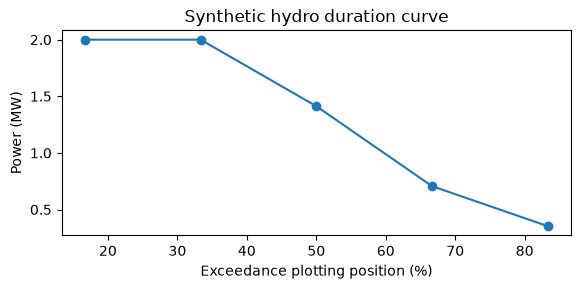

155.33088 MWh


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Step 1: Calculate daily average electrical powers.
power=np.minimum(1000*9.81*np.array([2,4,8,12,16])*20*0.9/1e6,2)
# Step 2: Sort only for the duration plot; integrate all equal-duration samples.
ranked=np.sort(power)[::-1]; energy=power.sum()*24
# Step 3: Plot the stated exceedance convention and check conservation of the sum.
fig,ax=plt.subplots(figsize=(6,3)); ax.plot(np.arange(1,6)/6*100,ranked,'o-')
ax.set(xlabel='Exceedance plotting position (%)',ylabel='Power (MW)',title='Synthetic hydro duration curve'); fig.tight_layout(); plt.show()
print(energy,'MWh'); assert np.isclose(ranked.sum()*24,energy)

**Interpretation:** Sorting preserves total energy for equal intervals but removes the order needed for storage simulation.


### Exercise 16 — Reservoir routing

**Difficulty:** Hard

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. Original chronological water-balance policy.

**Task:** Route hourly inflows [2, 0, 8, 16, 0, 0] m³/s from 20,000 m³ initial storage and a 50,000 m³ capacity. Prioritise an environmental release of up to 1 m³/s, then turbine flow of up to 3 m³/s. Spill the overflow. With net head 20 m and efficiency 0.9, report storage, spill and generation. Check the water balance in every interval.

In [ ]:
# Your solution for hydro exercise 16.

#### Step-by-step answer — Hydro 16

1. Set storage state and output records.
2. Allocate each hour of incoming water and spill overflow last.
3. Check total spill and final storage and report generated energy.

In [ ]:
import numpy as np
# Step 1: Set storage state and output records.
storage=20000.; rows=[]
# Step 2: Allocate each hour of incoming water and spill overflow last.
for q in [2,0,8,16,0,0]:
    before=storage; water=storage+q*3600
    environmental=min(water,3600); water-=environmental
    turbine=min(water,3*3600); water-=turbine
    spill=max(water-50000,0); storage=water-spill
    assert np.isclose(before+q*3600,storage+environmental+turbine+spill)
    energy=1000*9.81*turbine*20*0.9/3.6e9
    rows.append((storage,spill,energy,3600-environmental))
# Step 3: Check total spill and final storage and report generated energy.
total_spill=sum(r[1] for r in rows)
for hour, (stored, spilled, generated, shortage) in enumerate(rows, 1):
    print(f'Hour {hour}: storage {stored:.0f} m³, spill {spilled:.0f} m³, '
          f'energy {generated:.3f} MWh, environmental shortfall {shortage:.0f} m³')
print('Final storage:',storage,'m³; total spill:',total_spill,'m³; total generation:',sum(r[2] for r in rows),'MWh')
assert storage==21200 and total_spill==7600

**Interpretation:** Within-hour inflow is immediately available; head is constant and evaporation is omitted.


### Exercise 17 — Storage-dependent head

**Difficulty:** Hard

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. Storage–head relationship is synthetic.

**Task:** Route hourly inflows [2, 0, 3] m³/s from 20,000 m³ of storage. Withdraw up to 2 m³/s for generation and assume no overflow over these three hours. Use beginning-of-step head H = 10 + S/10,000 in metres with S in m³, and efficiency 0.9. Compare generation with a constant 12 m head.

In [ ]:
# Your solution for hydro exercise 17.

#### Step-by-step answer — Hydro 17

1. Initialise storage and energy counters.
2. Use beginning-of-step head and limit withdrawal to available water.
3. Compare model outputs and verify the final storage.

In [ ]:
import numpy as np
# Step 1: Initialise storage and energy counters.
storage=20000.; variable_energy=0.; fixed_energy=0.
# Step 2: Use beginning-of-step head and limit withdrawal to available water.
for inflow in [2,0,3]:
    before=storage; head=10+before/10000
    available=before+inflow*3600; volume=min(2*3600,available)
    storage=available-volume
    variable_energy+=1000*9.81*volume*head*0.9/3.6e9
    fixed_energy+=1000*9.81*volume*12*0.9/3.6e9
    assert np.isclose(before+inflow*3600,storage+volume)
# Step 3: Compare model outputs and verify the final storage.
print(variable_energy,fixed_energy,'MWh variable/fixed head')
assert storage==16400 and variable_energy<fixed_energy

0.62297424 0.635688 MWh variable/fixed head


**Interpretation:** Beginning-of-step head is a numerical approximation; smaller time steps may be needed for rapid level changes.


### Exercise 18 — Environmental-flow trade-off

**Difficulty:** Hard

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. Environmental flow is a scenario, not a regulatory recommendation.

**Task:** For daily river flows[2,5,8,12] m³/s, compare reservations 1,3,5 m³/s, head 30 m, eta 0.9, cap 2 MW. Calculate four-day energy and environmental-shortage volume.

In [ ]:
# Your solution for hydro exercise 18.

#### Step-by-step answer — Hydro 18

1. Keep the same river observations for every policy scenario.
2. Apply reservation, clipping and interval conversions.
3. Check the energy trade-off and report units.

In [ ]:
import numpy as np
# Step 1: Keep the same river observations for every policy scenario.
river=np.array([2,5,8,12]); results=[]
# Step 2: Apply reservation, clipping and interval conversions.
for reserve in [1,3,5]:
    usable=np.maximum(river-reserve,0)
    power=np.minimum(1000*9.81*usable*30*0.9/1e6,2)
    shortage=np.maximum(reserve-river,0).sum()*86400
    results.append((reserve,power.sum()*24,shortage))
# Step 3: Check the energy trade-off and report units.
print('Reservation m³/s, energy MWh, shortage m³:',results)
assert np.all(np.diff([r[1] for r in results])<=0)

Reservation m³/s, energy MWh, shortage m³: [(1, 124.28256, 0), (3, 92.49816, 86400), (5, 63.568799999999996, 259200)]


**Interpretation:** The model compares water allocation, not ecological adequacy or regulatory compliance.


### Exercise 19 — Search a generator rating

**Difficulty:** Hard

**Reference:** Head, discharge and electrical output: [Japan International Cooperation Agency, 2011](#reference-jica2011), Chapter 3 and §8.3; [International Finance Corporation, 2015](#reference-ifc2015), Chapter 7. Original capacity search.

**Task:** Flows[2,4,8,12] m³/s last 24 h each, head 30 m and eta 0.9. Choose the smallest candidate rating[1,2,3,4] MW that captures 95% of uncapped energy.

In [ ]:
# Your solution for hydro exercise 19.

#### Step-by-step answer — Hydro 19

1. Calculate the uncapped electrical resource.
2. Evaluate retained energy for each candidate rating.
3. Select and verify the first feasible rating.

In [ ]:
import numpy as np
# Step 1: Calculate the uncapped electrical resource.
available=1000*9.81*np.array([2,4,8,12])*30*0.9/1e6
# Step 2: Evaluate retained energy for each candidate rating.
results=[(r,np.minimum(available,r).sum()/available.sum()) for r in [1,2,3,4]]
# Step 3: Select and verify the first feasible rating.
best=next(row for row in results if row[1]>=0.95)
print('MW rating, retained energy fraction:',best); assert best[0]==3

MW rating, retained energy fraction: (3, 0.9740888854038701)


**Interpretation:** This is an energy-capture criterion; construction cost and seasonal hydrology are not represented.


### Exercise 20 — Pumped-storage dispatch and water balance

**Difficulty:** Hard

**Reference:** Pumped storage: [Quaranta et al., 2025](#reference-jrc2025hydro), §2; original dispatch and water balance.

**Task:** An upper reservoir starts empty with capacity 10000 m³ and head 100 m. Pump with 1 MW for two hours at 85%, then generate for two hours at up to 0.7 MW and 90%. Track water and electricity.

In [ ]:
# Your solution for hydro exercise 20.

#### Step-by-step answer — Hydro 20

1. Set state and energy totals at constant head.
2. Limit pumping by space and generation by available water.
3. Account for remaining stored energy as well as conversion losses.

In [ ]:
import numpy as np
# Step 1: Set state and energy totals at constant head.
storage=0.; used=0.; recovered=0.; joules_per_m3=1000*9.81*100
# Step 2: Limit pumping by space and generation by available water.
for hour, action in enumerate(['pump','pump','generate','generate'], 1):
    before=storage
    if action=='pump':
        volume=min(1e6*3600*0.85/joules_per_m3,10000-storage)
        storage+=volume; used+=volume*joules_per_m3/0.85/3.6e9
    else:
        volume=min(0.7e6*3600/(joules_per_m3*0.9),storage)
        storage-=volume; recovered+=volume*joules_per_m3*0.9/3.6e9
    change = volume if action=='pump' else -volume
    assert 0<=storage<=10000 and np.isclose(before+change,storage)
    print(f'Hour {hour} ({action}): moved {volume:.1f} m³, stored {storage:.1f} m³')
# Step 3: Account for remaining stored energy as well as conversion losses.
stored_equivalent=storage*joules_per_m3*0.9/3.6e9
print(used,recovered,stored_equivalent,'MWh pumping, exported, recoverable remaining')
assert np.isclose(recovered+stored_equivalent,used*0.85*0.9)

**Interpretation:** The final reservoir need not be empty; recovered/pumped energy over a partial cycle is not full round-trip efficiency.



## References used in this notebook

<a id="reference-jica2011"></a>

- **jica2011:** Japan International Cooperation Agency. Guideline and Manual for Hydropower Development, Vol. 2: Small Scale Hydropower (2011). 
<a id="reference-ifc2015"></a>

- **ifc2015:** International Finance Corporation. Hydroelectric Power: A Guide for Developers and Investors (2015). 
<a id="reference-jrc2025hydro"></a>

- **jrc2025hydro:** Quaranta, Emanuele and Georgakaki, Aliki and Letout, Sylvain and Mountraki, Agnieszka and Ince, Ebru and others. Clean Energy Technology Observatory: Hydropower and Pumped Storage Hydropower in the European Union — 2025 Status Report on Technology Development, Trends, Value Chains and Markets (2025). 
<a id="reference-wade2003"></a>

- **wade2003:** Wade, Herbert A.. Solar Photovoltaic Systems: Technical Training Manual (2003). 
<a id="reference-matplotlibDocs"></a>

- **matplotlibDocs:** Matplotlib Developers. Matplotlib User Guide (2026). https://matplotlib.org/stable/users/index.html